# Visualize the Boundary Detectors in Hierarchical SNN

In [10]:
# visualize the boundary detectors in the hierarchical SNN
import torch

import os
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt

from dataloader import train_test_val_split, get_dataset_statistics
from models import TwoLayer_HierarchicalSNN, ThreeLayer_HierarchicalSNN, create_model
from utils.encoding import Current_Encoder
import utils.metrics as metrics

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
# set seeds
seed = 42
device = 'cpu'
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
torch.manual_seed(seed)

In [3]:
# Configure dataset
binary = True
dataset_configs = {
    "data_file": "/Users/rahul/Documents/Milstein_lab/arrhythmia_detection/beats/data.hdf5",
    "metadata": "/Users/rahul/Documents/Milstein_lab/arrhythmia_detection/beats/data.csv",
    "train_prop": 0.6,
    "val_prop": 0.2,
    "test_prop": 0.2,
    "binary": binary,
    "random_state": 2,
    "balance": True,
    "fourier": False,
}

# Get Datasets and Dataset Stats
train_dataset, val_dataset, test_dataset = train_test_val_split(**dataset_configs)
train_mean, train_std = get_dataset_statistics(train_dataset)
encoder = Current_Encoder(train_mean, train_std)

In [14]:
model_name = 'hgrsnn'
weight_folder = '../remote_weights_OLD/model_weights'
model_weight = 's_2_optimized_threelayer_hsnn_32_64_lif'
with open('nested_configs/hgrsnn_config.yaml', 'r') as file:
    model_configs = yaml.safe_load(file)

model = create_model(model_configs)

model_path = os.path.join(weight_folder, model_weight) + '.pth'
checkpoint = torch.load(model_path, weights_only=False)
model.load_state_dict(checkpoint['model'])

val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=128)
threshold = metrics.get_threshold(model, val_loader, encoder, fix_sensitivity=True)
print(threshold)

1.0


In [15]:
for i in range(len(test_dataset)):
    w, l = test_dataset.__getitem__(i)
    
    if l[0] != 0:
        print(f'({l[0]}, {i})', end='\t')

(1.0, 0)	(1.0, 1)	(1.0, 2)	(1.0, 3)	(1.0, 4)	(1.0, 6)	(1.0, 7)	(1.0, 8)	(1.0, 10)	(1.0, 13)	(1.0, 14)	(1.0, 16)	(1.0, 18)	(1.0, 21)	(1.0, 24)	(1.0, 25)	(1.0, 28)	(1.0, 29)	(1.0, 30)	(1.0, 31)	(1.0, 34)	(1.0, 35)	(1.0, 38)	(1.0, 39)	(1.0, 40)	(1.0, 43)	(1.0, 46)	(1.0, 51)	(1.0, 52)	(1.0, 53)	(1.0, 54)	(1.0, 56)	(1.0, 57)	(1.0, 59)	(1.0, 60)	(1.0, 62)	(1.0, 63)	(1.0, 65)	(1.0, 67)	(1.0, 68)	(1.0, 70)	(1.0, 71)	(1.0, 74)	(1.0, 76)	(1.0, 78)	(1.0, 80)	(1.0, 81)	(1.0, 82)	(1.0, 83)	(1.0, 86)	(1.0, 89)	(1.0, 90)	(1.0, 92)	(1.0, 98)	(1.0, 99)	(1.0, 101)	(1.0, 102)	(1.0, 103)	(1.0, 104)	(1.0, 108)	(1.0, 109)	(1.0, 111)	(1.0, 112)	(1.0, 113)	(1.0, 115)	(1.0, 116)	(1.0, 117)	(1.0, 118)	(1.0, 119)	(1.0, 123)	(1.0, 124)	(1.0, 128)	(1.0, 129)	(1.0, 132)	(1.0, 134)	(1.0, 136)	(1.0, 137)	(1.0, 138)	(1.0, 141)	(1.0, 142)	(1.0, 143)	(1.0, 146)	(1.0, 148)	(1.0, 149)	(1.0, 152)	(1.0, 153)	(1.0, 158)	(1.0, 162)	(1.0, 163)	(1.0, 164)	(1.0, 168)	(1.0, 169)	(1.0, 171)	(1.0, 173)	(1.0, 174)	(1.0, 175)	(1.0, 1

Text(0.5, 1.0, 'Class: 0.0')

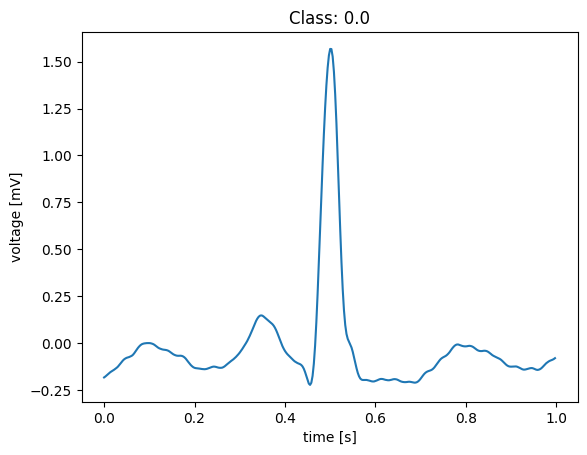

In [26]:
waveform, label = test_dataset.__getitem__(9)

ts = np.arange(len(waveform)) / 360
plt.plot(ts, waveform);
plt.xlabel('time [s]')
plt.ylabel('voltage [mV]');
plt.title(f'Class: {label[0]}')

In [27]:
with torch.no_grad():
    waveform_for_model = encoder.encode(waveform.unsqueeze(0))
    prediction, _, b_vals  = model(waveform_for_model, logging=True)
    prediction = int(prediction.sum(dim=(1,2)).item() > threshold)

print('Predicted Class: {}'.format(prediction)) 

Predicted Class: 0


In [28]:
b_0, b_1, b_2 = b_vals
b_0 = b_0.squeeze().numpy()
b_1 = b_1.squeeze().numpy()
b_2 = b_2.squeeze().numpy()

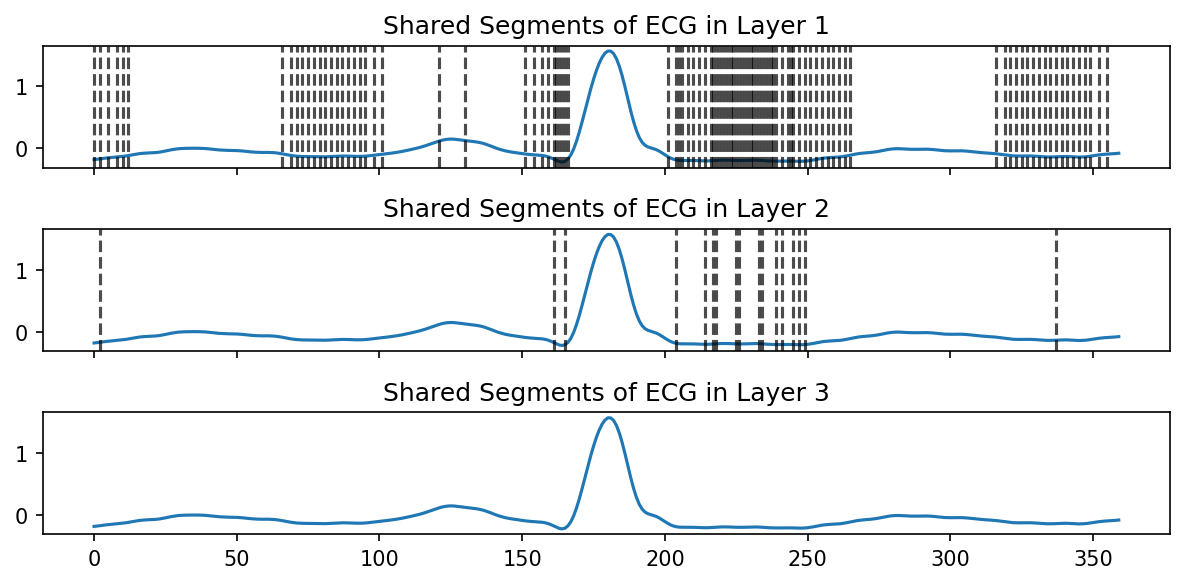

In [29]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(8, 4), gridspec_kw={'height_ratios': [3, 3, 3]}, dpi=150)

x = np.arange(len(b_0))
b_0_indeces = np.where(b_0 == 1)[0]
event_times = x[b_0_indeces]

ax1.plot(x, waveform)
for t in event_times:
    ax1.axvline(t, color='black', linestyle='--', alpha=0.7)

b_1_indeces = np.where(b_1 == 1)[0]
event_times = x[b_1_indeces]

ax2.plot(x, waveform)
for t in event_times:
    ax2.axvline(t, color='black', linestyle='--', alpha=0.7)

b_2_indeces = np.where(b_2 == 1)[0]
event_times = x[b_2_indeces]

ax3.plot(x, waveform)
for t in event_times:
    ax3.axvline(t, color='black', linestyle='--', alpha=0.7)


ax1.set_title('Shared Segments of ECG in Layer 1')
ax2.set_title('Shared Segments of ECG in Layer 2')
ax3.set_title('Shared Segments of ECG in Layer 3')

fig.tight_layout()


In [37]:
negative_waveform, label = test_dataset.__getitem__(9)

with torch.no_grad():
    negative_waveform_for_model = encoder.encode(negative_waveform.unsqueeze(0))
    negative_prediction, _, b_vals  = model(negative_waveform_for_model, logging=True)
    negative_prediction = int(negative_prediction.sum(dim=(1,2)).item() > threshold)

print('Predicted Class: {}, Real Class: {}'.format(negative_prediction, label[0])) 

neg_b_0, neg_b_1, neg_b_2 = b_vals
neg_b_0 = neg_b_0.squeeze().numpy()
neg_b_1 = neg_b_1.squeeze().numpy()
neg_b_2 = neg_b_2.squeeze().numpy()

positive_waveform, label = test_dataset.__getitem__(16)

with torch.no_grad():
    positive_waveform_for_model = encoder.encode(positive_waveform.unsqueeze(0))
    positive_prediction, _, b_vals  = model(positive_waveform_for_model, logging=True)
    positive_prediction = int(positive_prediction.sum(dim=(1,2)).item() > threshold)

print('Predicted Class: {}, Real Class: {}'.format(positive_prediction, label[0])) 

pos_b_0, pos_b_1, pos_b_2 = b_vals
pos_b_0 = pos_b_0.squeeze().numpy()
pos_b_1 = pos_b_1.squeeze().numpy()
pos_b_2 = pos_b_2.squeeze().numpy()

Predicted Class: 0, Real Class: 0.0
Predicted Class: 1, Real Class: 1.0


In [39]:
pos_example, label = test_dataset.__getitem__(16)

for i, (_, label) in enumerate(test_dataset):
    print(i, label.max())

0 tensor(1.)
1 tensor(1.)
2 tensor(1.)
3 tensor(1.)
4 tensor(1.)
5 tensor(0.)
6 tensor(1.)
7 tensor(1.)
8 tensor(1.)
9 tensor(0.)
10 tensor(1.)
11 tensor(0.)
12 tensor(0.)
13 tensor(1.)
14 tensor(1.)
15 tensor(0.)
16 tensor(1.)
17 tensor(0.)
18 tensor(1.)
19 tensor(0.)
20 tensor(0.)
21 tensor(1.)
22 tensor(0.)
23 tensor(0.)
24 tensor(1.)
25 tensor(1.)
26 tensor(0.)
27 tensor(0.)
28 tensor(1.)
29 tensor(1.)
30 tensor(1.)
31 tensor(1.)
32 tensor(0.)
33 tensor(0.)
34 tensor(1.)
35 tensor(1.)
36 tensor(0.)
37 tensor(0.)
38 tensor(1.)
39 tensor(1.)
40 tensor(1.)
41 tensor(0.)
42 tensor(0.)
43 tensor(1.)
44 tensor(0.)
45 tensor(0.)
46 tensor(1.)
47 tensor(0.)
48 tensor(0.)
49 tensor(0.)
50 tensor(0.)
51 tensor(1.)
52 tensor(1.)
53 tensor(1.)
54 tensor(1.)
55 tensor(0.)
56 tensor(1.)
57 tensor(1.)
58 tensor(0.)
59 tensor(1.)
60 tensor(1.)
61 tensor(0.)
62 tensor(1.)
63 tensor(1.)
64 tensor(0.)
65 tensor(1.)
66 tensor(0.)
67 tensor(1.)
68 tensor(1.)
69 tensor(0.)
70 tensor(1.)
71 tensor(1.)
72

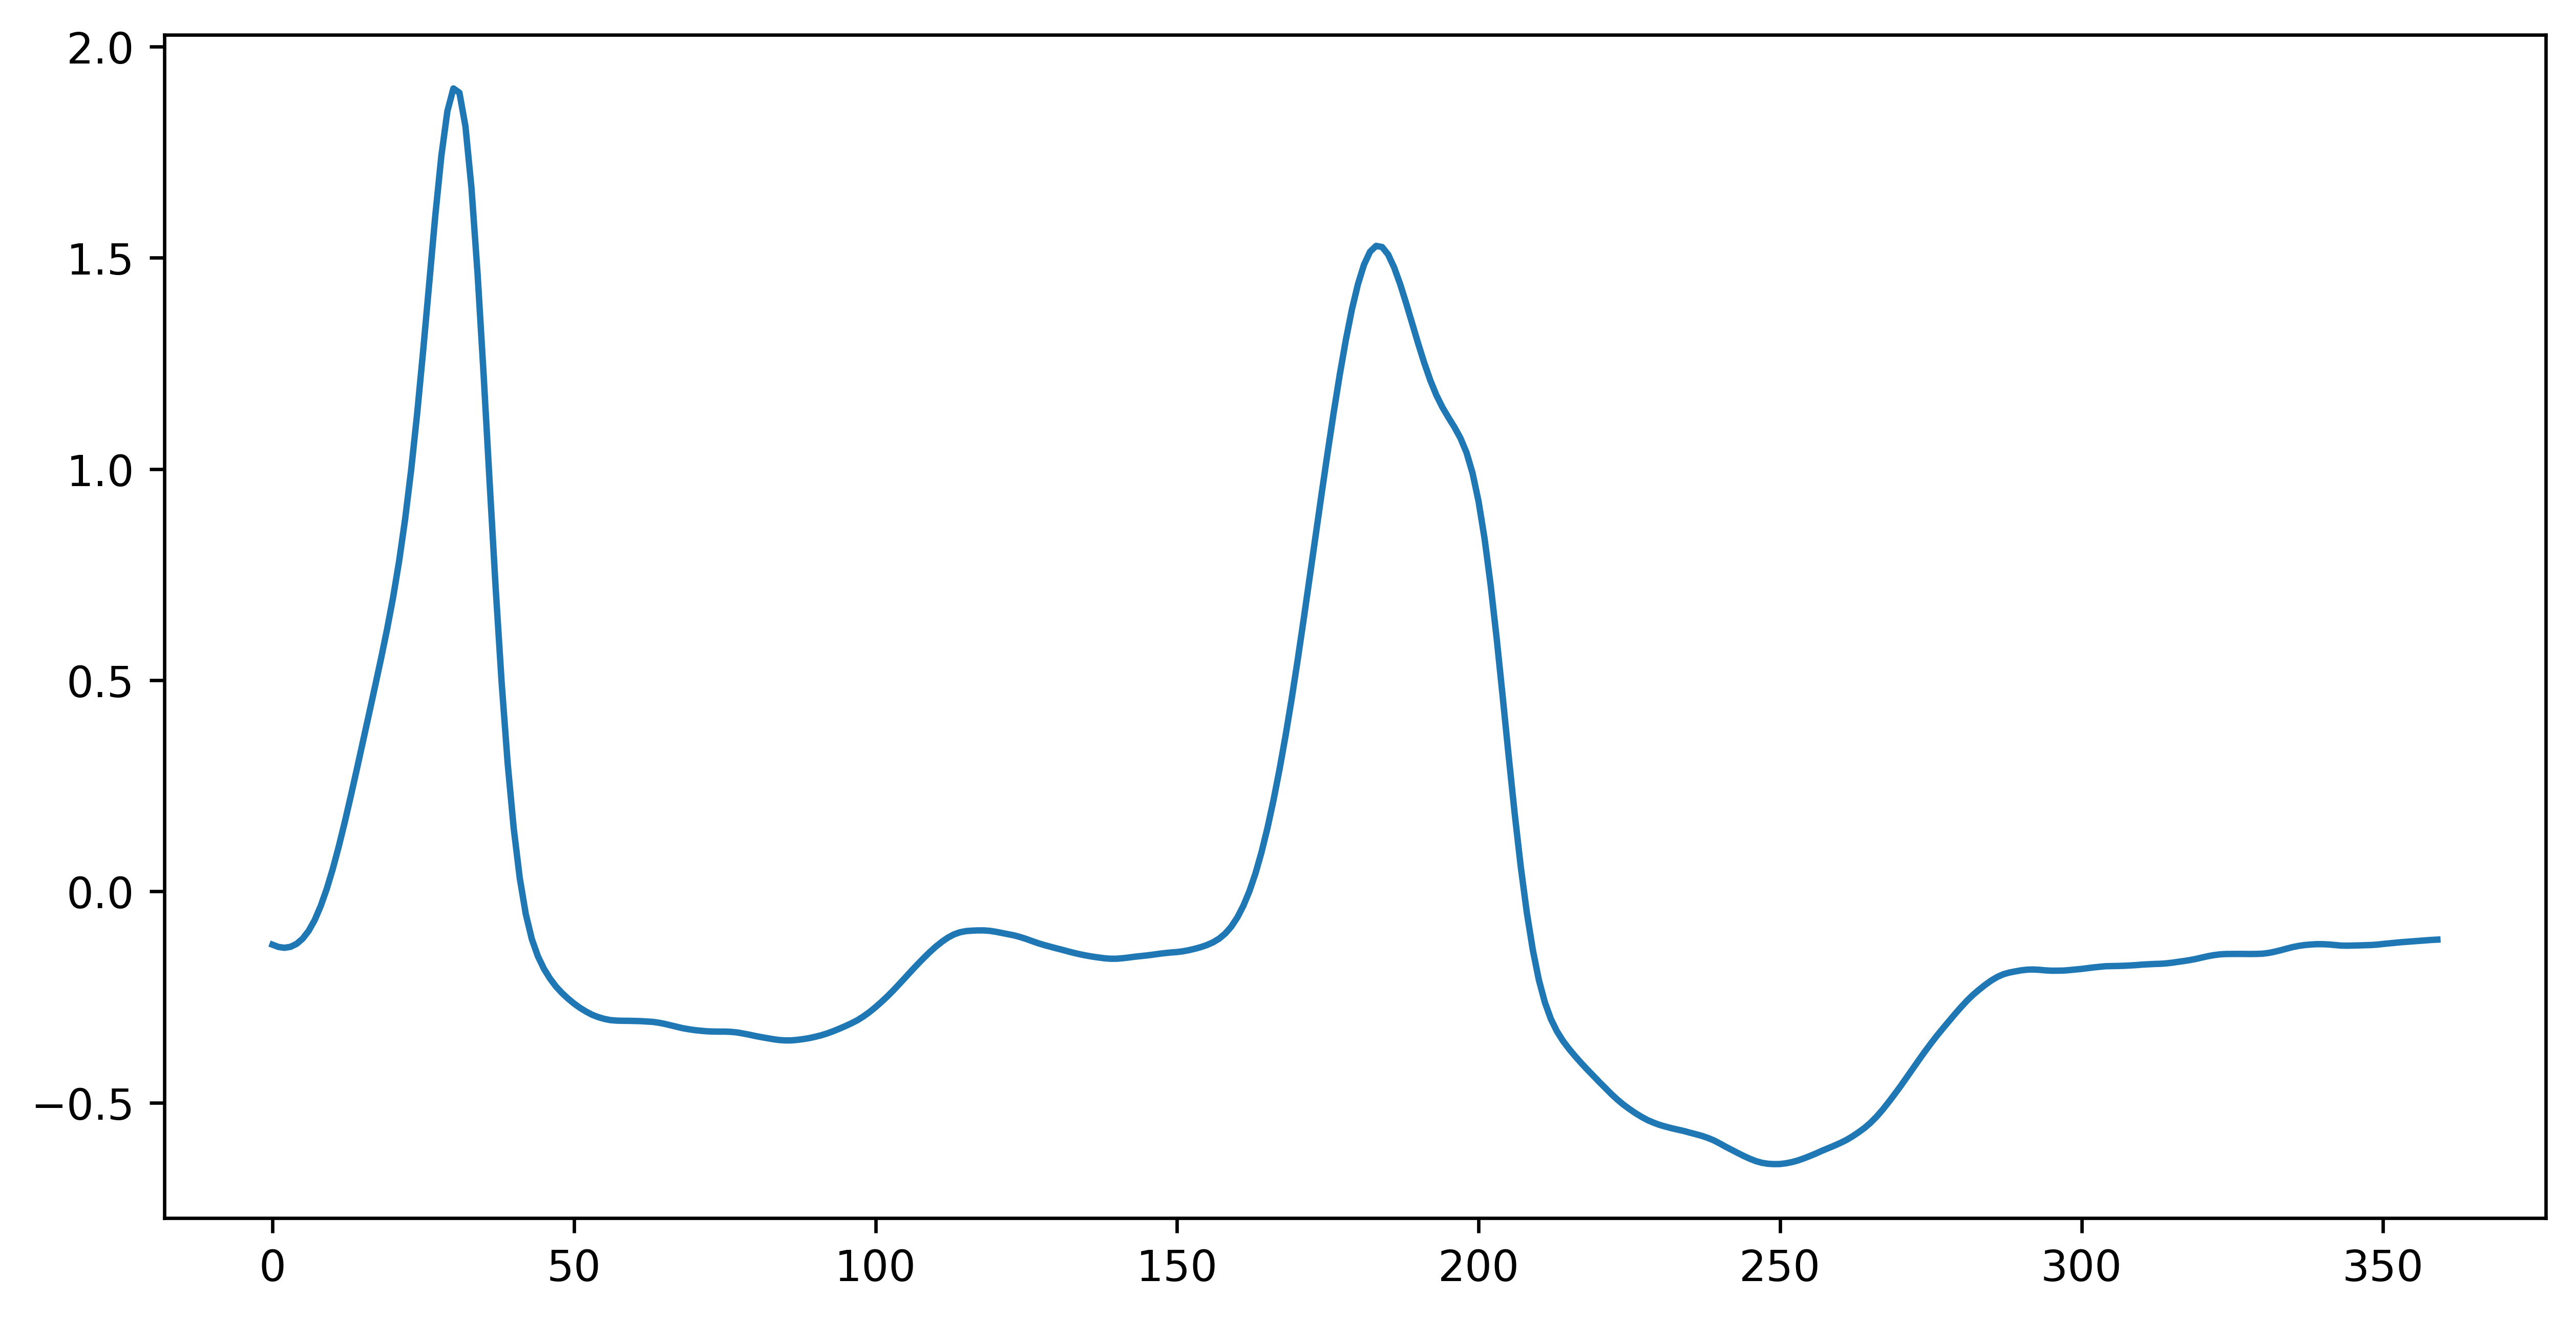

In [40]:
fig, axes = plt.subplots(1, 1, figsize=(10, 5), dpi=600)

# x axes
x_pos = np.arange(len(pos_example))

axes.plot(x_pos, pos_example)

plt.show()


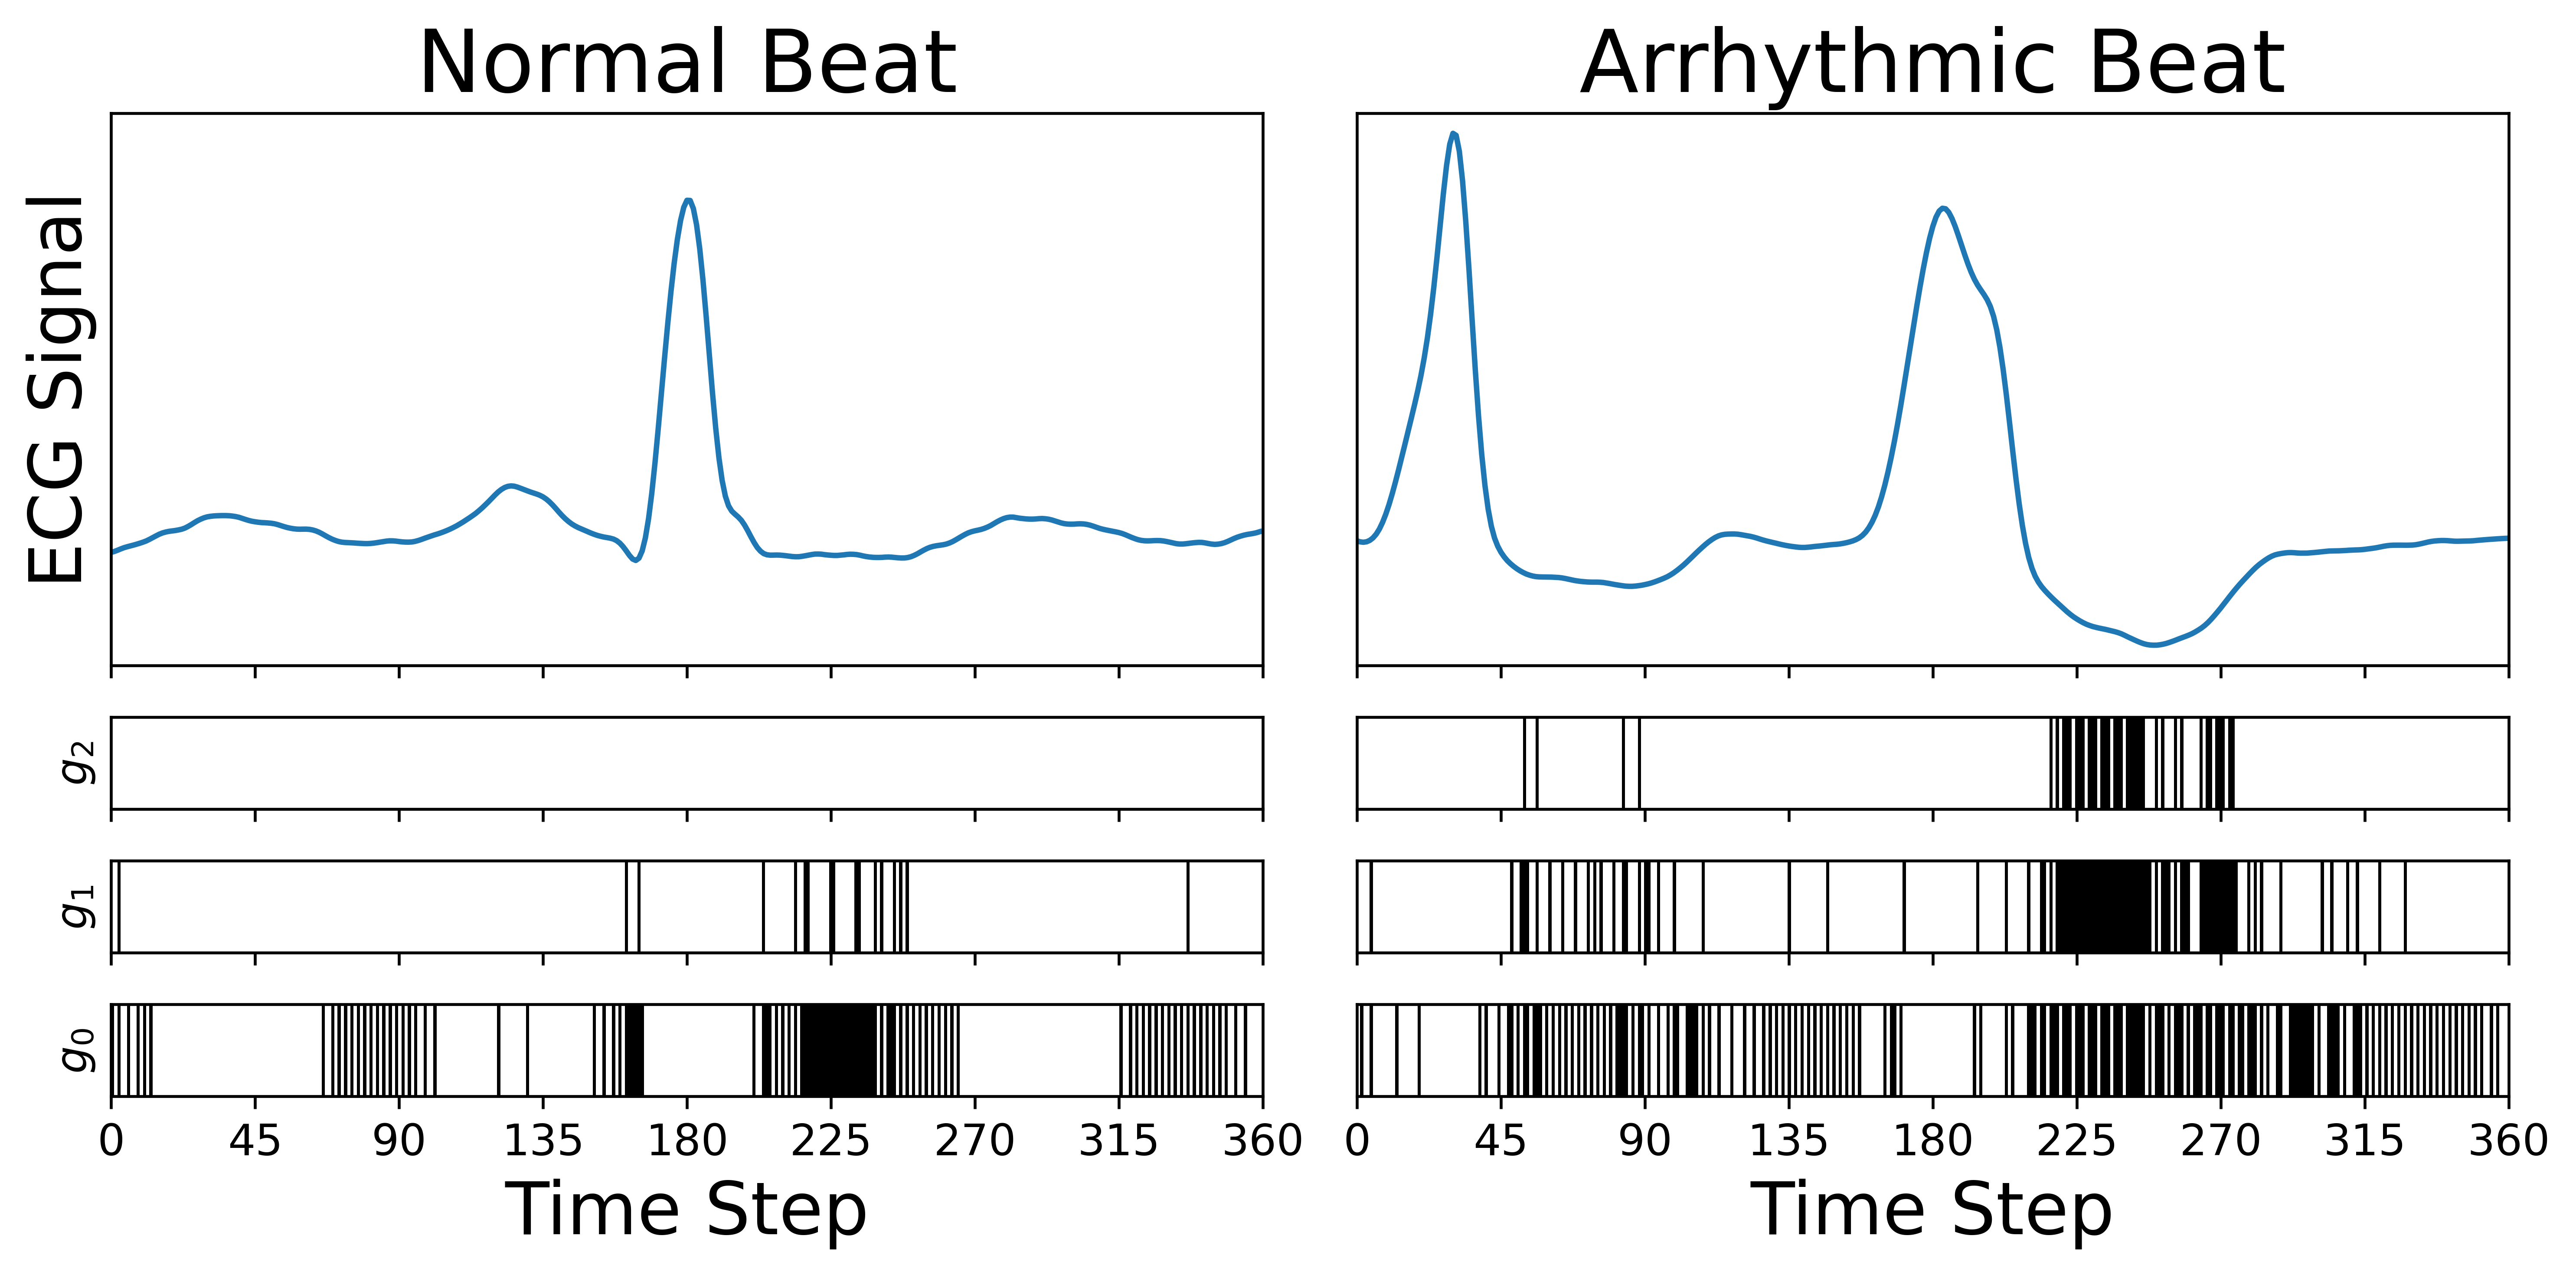

In [41]:
fig, axes = plt.subplots(
    4, 2,
    sharex='col',
    figsize=(10, 5),
    gridspec_kw={'height_ratios': [3, 0.5, 0.5, 0.5]},
    dpi=600,
)

# x axes
x_neg = np.arange(len(neg_b_0))
x_pos = np.arange(len(pos_b_0))

# -------------------
# LEFT COLUMN: Negative
# -------------------
axes[0, 0].plot(x_neg, negative_waveform, )
axes[1, 0].imshow(neg_b_2[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)
axes[2, 0].imshow(neg_b_1[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)
axes[3, 0].imshow(neg_b_0[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_neg[0], x_neg[-1], 0, 1], vmin=0, vmax=1)

# -------------------
# RIGHT COLUMN: Positive
# -------------------
axes[0, 1].plot(x_pos, positive_waveform)
axes[1, 1].imshow(pos_b_2[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)
axes[2, 1].imshow(pos_b_1[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)
axes[3, 1].imshow(pos_b_0[np.newaxis, :], aspect='auto', cmap='gray_r',
                  extent=[x_pos[0], x_pos[-1], 0, 1], vmin=0, vmax=1)

# -------------------
# Formatting
# -------------------
for col in range(2):
    for row in range(4):
        axes[row, col].set_yticks([])
        axes[row, col].set_xlim(0,max(len(neg_b_0), len(pos_b_0)) - 1)
        axes[row, col].set_xticks([0, 45, 90, 135, 180, 225, 270, 315, 360])
        axes[row, col].tick_params(axis='x', labelsize=12)

y_min = min(negative_waveform.min(), positive_waveform.min()) - 0.1
y_max = max(negative_waveform.max(), positive_waveform.max()) + 0.1

axes[0, 0].set_ylim(y_min, y_max)
axes[0, 1].set_ylim(y_min, y_max)

# Row labels
axes[0, 0].set_ylabel('ECG Signal', fontsize=20,)
axes[1, 0].set_ylabel('$g_2$', fontsize=12,)
axes[2, 0].set_ylabel('$g_1$', fontsize=12,)
axes[3, 0].set_ylabel('$g_0$', fontsize=12,)

# Column titles
axes[0, 0].set_title('Normal Beat', fontsize=24, )
axes[0, 1].set_title('Arrhythmic Beat', fontsize=24, )

# X labels
axes[3, 0].set_xlabel('Time Step', fontsize=20)
axes[3, 1].set_xlabel('Time Step', fontsize=20)

plt.tight_layout()
plt.savefig("../figures/gate_visualization_transparent.png", dpi=600, bbox_inches="tight", transparent=True)

plt.show()


## Check Linear Baseline

In [21]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

def train_pca_lda(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("clf", LinearDiscriminantAnalysis())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

def train_pca_logreg(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("clf", LogisticRegression())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

def train_logreg(X_train, y_train, X_test, y_test, n_components=10):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression())
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    return model

In [22]:
train_X = []
train_y = []

for i in range(len(train_dataset)):
    w, l = train_dataset.__getitem__(i)
    train_X.append(w)
    train_y.append(l[0])

train_X = np.stack(train_X)
train_y = np.stack(train_y)

test_X = []
test_y = []

for i in range(len(test_dataset)):
    w, l = test_dataset.__getitem__(i)
    test_X.append(w)
    test_y.append(l[0])

test_X = np.stack(test_X)
test_y = np.stack(test_y)


In [23]:
logreg_model = train_logreg(train_X, train_y, test_X, test_y, n_components=100)

Accuracy: 0.7451499952682881
              precision    recall  f1-score   support

         0.0       0.72      0.78      0.75      5123
         1.0       0.77      0.71      0.74      5444

    accuracy                           0.75     10567
   macro avg       0.75      0.75      0.75     10567
weighted avg       0.75      0.75      0.75     10567



/Users/rahul/anaconda3/envs/arr/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7461490141920943


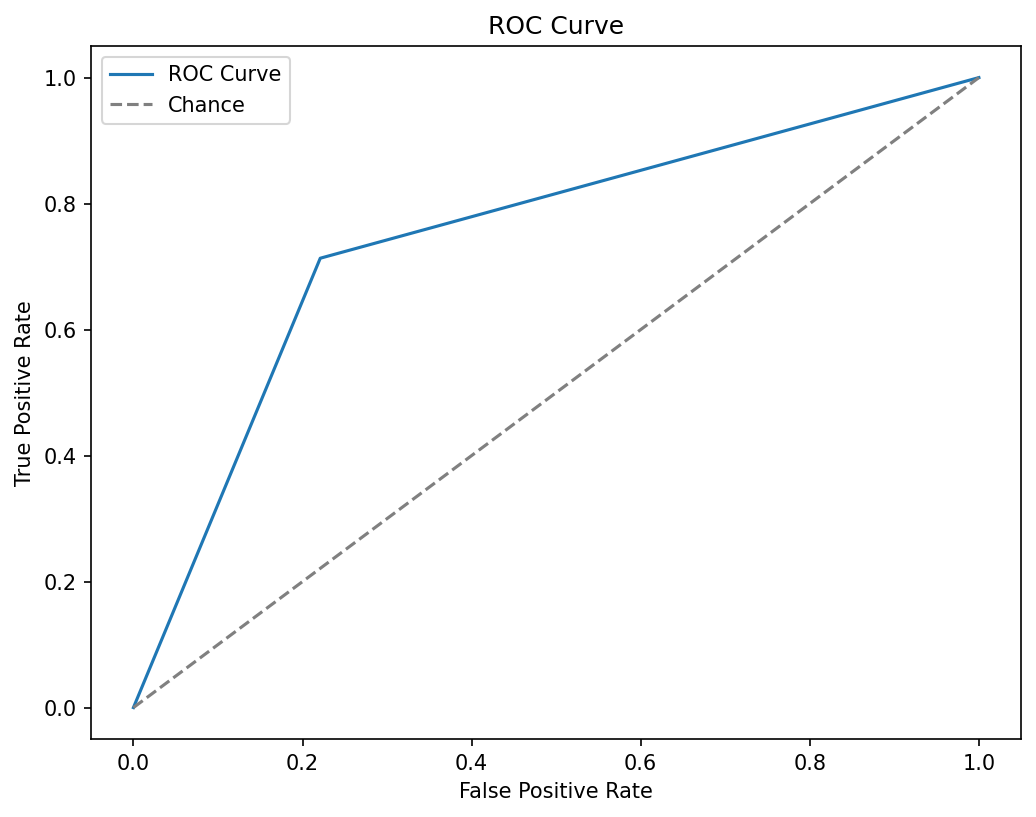

In [24]:
predictions = logreg_model.predict(test_X)

fpr, tpr, thresholds = roc_curve(test_y, predictions)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

ax.plot(fpr, tpr, label='ROC Curve')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()

print(auc(fpr, tpr))

## Check Class-Wise Accuracy

In [25]:
model_name = 'hgrsnn_v1'
weight_folder = '../presentation_results/model_weights'
model_weight = 's_0_hgrsnn_v1'
with open('nested_configs/hgrsnn_v1_config.yaml', 'r') as file:
    model_configs = yaml.safe_load(file)

model = create_model(model_configs)

model_path = os.path.join(weight_folder, model_weight) + '.pth'
checkpoint = torch.load(model_path, weights_only=False)
model.load_state_dict(checkpoint['model'])

val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=128)
threshold = metrics.get_threshold(model, val_loader, encoder, fix_sensitivity=True)
print(threshold)

2.0


In [26]:
# the dataset was built with binary=True, so __getitem__ returns 0/1 labels.
# the underlying AAMI class is still in test_dataset.metadata['label'], and
# metadata rows are indexed with .iloc in __getitem__, so an unshuffled
# DataLoader walks the test set in metadata row order.
AAMI_CLASSES = {0: 'N (normal)', 1: 'S (supraventricular)', 2: 'V (ventricular)',
                3: 'F (fusion)'}

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

scores = []
model.eval()
with torch.no_grad():
    for data, _ in test_loader:
        data = encoder.encode(data).to(device)
        output, _ = model(data)
        scores.append(output.sum(dim=(1, 2)).cpu().numpy())

scores = np.concatenate(scores)
y_pred = (scores > threshold).astype(int)

y_multi = test_dataset.metadata['label'].to_numpy()
y_binary = (y_multi > 0).astype(int)

print('Overall binary accuracy: {:.4f}\n'.format((y_pred == y_binary).mean()))

print(f"{'class':<24}{'n':>6}{'accuracy':>10}")
for c in np.unique(y_multi):
    mask = y_multi == c
    # for class 0 "correct" means predicting normal; for any other class it
    # means predicting arrhythmic, so this is recall within each true class
    acc = (y_pred[mask] == y_binary[mask]).mean()
    print(f'{AAMI_CLASSES.get(c, str(c)):<24}{mask.sum():>6}{acc:>10.4f}')


Overall binary accuracy: 0.6525

class                        n  accuracy
N (normal)                5123    0.5253
S (supraventricular)      1837    0.3468
V (ventricular)           3219    0.9894
F (fusion)                 388    0.9845


Text(0.5, 1.0, 'Class: 1.0')

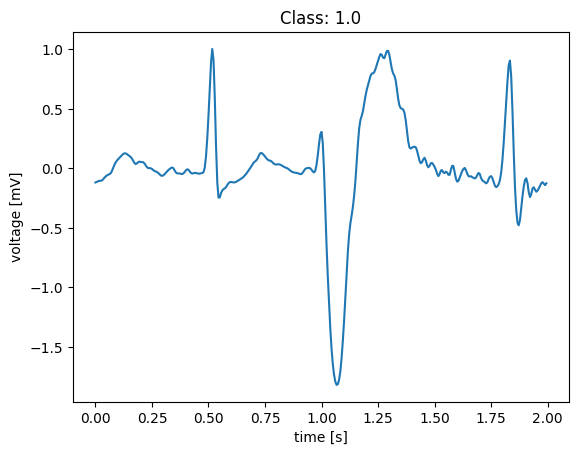

In [15]:
waveform, label = test_dataset.__getitem__(16)

ts = np.arange(len(waveform)) / 180
plt.plot(ts, waveform);
plt.xlabel('time [s]')
plt.ylabel('voltage [mV]');
plt.title(f'Class: {label[0]}')

In [16]:
waveform.shape

torch.Size([360])